# TP4 — Scaled Multiple Linear Regression

## Why scaling matters

TV, Radio, and Newspaper budgets do not have identical ranges. Without
scaling, the gradient can be dominated by the largest numerical feature and
the optimisation path may zig-zag or converge very slowly.

Standardisation is fitted on the training data only:

$$
z=\frac{x-\mu_{train}}{\sigma_{train}}
$$

The same $\mu_{train}$ and $\sigma_{train}$ are then applied to the test data.
This prevents test-set information from leaking into training. After scaling,
the notebook trains a from-scratch model and compares it with scikit-learn.

## Mathematical foundations

For a linear model, the prediction is the weighted sum of the input features:

$$
\hat{y} = X\theta
$$

The notebooks add a column of ones to $X$ when the intercept is learned as one
of the parameters in $\theta$. The objective is the half mean-squared error:

$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}(\hat{y}^{(i)}-y^{(i)})^2
$$

Its gradient is:

$$
\nabla_\theta J(\theta) = \frac{1}{m}X^T(X\theta-y)
$$

Gradient descent repeatedly updates the parameters in the direction that
reduces the cost:

$$
\theta \leftarrow \theta - \alpha\nabla_\theta J(\theta)
$$

where $m$ is the number of observations and $\alpha$ is the learning rate.
Model quality is reported with mean squared error and the coefficient of
determination:

$$
\mathrm{MSE}=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2,
\qquad
R^2=1-\frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}
$$


# **TP3 : RÃ©gression LinÃ©aire Multiple**
**Module :** Machine Learning  
**Sujet :** RÃ©gression linÃ©aire multiple par descente de gradient (*from scratch*) et comparaison avec Scikit-learn


## **Section 1 : Introduction au TP**
Ce notebook prÃ©sente l'implÃ©mentation complÃ¨te d'un modÃ¨le de **rÃ©gression linÃ©aire multiple** Ã  partir de zÃ©ro (*from scratch*) en utilisant l'algorithme de **descente de gradient**, ainsi qu'une comparaison avec l'implÃ©mentation de la bibliothÃ¨que **Scikit-learn**.

#### **Objectifs du TP**
1. Comprendre les fondements mathÃ©matiques de la rÃ©gression linÃ©aire multiple.
2. ImplÃ©menter manuellement le calcul de la prÃ©diction, du coÃ»t (MSE) et la mise Ã  jour des paramÃ¨tres (descente de gradient).
3. Standardiser les variables d'entrÃ©e pour assurer une convergence stable de l'optimiseur.
4. Comparer les performances ($R^2$ et $MSE$) de notre algorithme avec `LinearRegression` de Scikit-learn.

#### **ModÃ¨le mathÃ©matique**
Le modÃ¨le de rÃ©gression linÃ©aire multiple s'Ã©crit :
$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n$$

OÃ¹ :
* $\hat{y}$ est la prÃ©diction de la variable cible (*Sales*) ;
* $x_1, x_2, \dots, x_n$ sont les caractÃ©ristiques (TV, Radio, Newspaper) ;
* $\theta_1, \dots, \theta_n$ sont les coefficients (poids) associÃ©s aux caractÃ©ristiques ;
* $\theta_0$ est l'ordonnÃ©e Ã  l'origine (*intercept* ou *biais*).


### **Importation des bibliothÃ¨ques**
* `pandas` : lecture et manipulation du jeu de donnÃ©es ;
* `numpy` : calcul matriciel ;
* `matplotlib` : visualisation ;
* `scikit-learn` : sÃ©paration train/test, standardisation, mÃ©triques et modÃ¨le de rÃ©fÃ©rence.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # nÃ©cessaire pour les graphiques 3D
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

%matplotlib inline

## **Section 2 : Exploration du jeu de donnÃ©es**
Nous chargeons le fichier `data/Advertising.csv` contenant les budgets publicitaires allouÃ©s Ã  trois canaux de communication (**TV**, **Radio**, **Newspaper**) ainsi que les ventes correspondantes (**Sales**).

*Remarque : le fichier `data/Advertising.csv` doit se trouver dans le mÃªme dossier que ce notebook.*


In [4]:
# Chargement du jeu de donnÃ©es
dataset = pd.read_csv("data/Advertising.csv")

AperÃ§u des cinq premiÃ¨res lignes du jeu de donnÃ©es :


In [5]:
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Nous extrayons chaque colonne dans une variable distincte, puis nous visualisons les donnÃ©es en 3D : les trois axes reprÃ©sentent les budgets (TV, Radio, Newspaper) et la couleur des points reprÃ©sente les ventes (*Sales*).


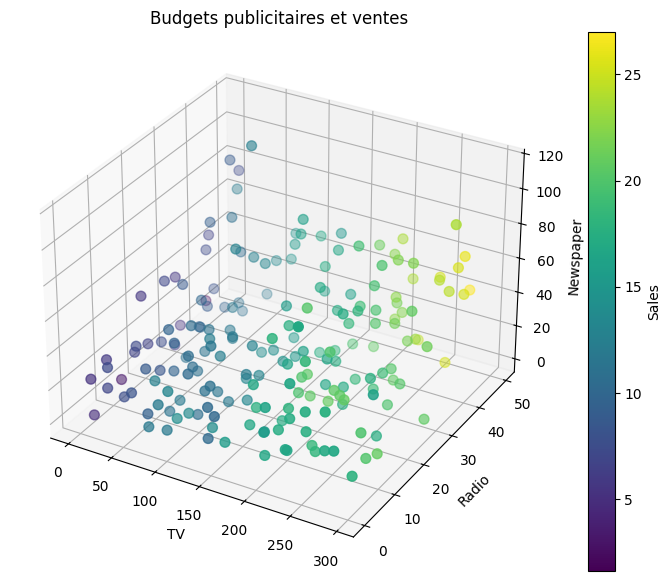

In [6]:
X1 = dataset["TV"]
X2 = dataset["Radio"]
X3 = dataset["Newspaper"]
Y  = dataset["Sales"]

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(X1, X2, X3, c=Y, cmap="viridis", s=50)

ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Newspaper")
ax.set_title("Budgets publicitaires et ventes")

cbar = plt.colorbar(sc)
cbar.set_label("Sales")

plt.show()

VÃ©rification des dimensions de chaque variable (chacune doit contenir 200 observations) :


In [7]:
print("X1 (TV)        :", X1.shape)
print("X2 (Radio)     :", X2.shape)
print("X3 (Newspaper) :", X3.shape)
print("Y  (Sales)     :", Y.shape)

X1 (TV)        : (200,)
X2 (Radio)     : (200,)
X3 (Newspaper) : (200,)
Y  (Sales)     : (200,)


## **Section 3 : SÃ©paration des caractÃ©ristiques (features) et de la cible (target)**
Nous isolons les variables d'entrÃ©e $X$ (TV, Radio, Newspaper) de la variable Ã  prÃ©dire $y$ (Sales).

* $Y$ est transformÃ© en **vecteur colonne** de forme $(m, 1)$ afin d'Ãªtre compatible avec les opÃ©rations matricielles.
* $X$ est construit en assemblant les trois colonnes : sa forme est $(m, 3)$.


In [8]:
Y = dataset["Sales"].values.reshape(-1, 1)
print("Forme de Y :", Y.shape)

X = np.column_stack((X1, X2, X3))
print("Forme de X :", X.shape)

Forme de Y : (200, 1)
Forme de X : (200, 3)


## **Section 4 : Division en donnÃ©es d'entraÃ®nement et de test**
Nous divisons nos 200 observations en :
* un ensemble d'**entraÃ®nement** ($80\%$) pour ajuster le modÃ¨le ;
* un ensemble de **test** ($20\%$), indÃ©pendant, pour Ã©valuer sa capacitÃ© de gÃ©nÃ©ralisation.

Le paramÃ¨tre `random_state=42` rend la division reproductible.


In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("Y_train :", Y_train.shape)
print("Y_test  :", Y_test.shape)

X_train : (160, 3)
X_test  : (40, 3)
Y_train : (160, 1)
Y_test  : (40, 1)


## **Section 5 : Standardisation des caractÃ©ristiques**
La descente de gradient converge beaucoup plus efficacement lorsque les caractÃ©ristiques ont des Ã©chelles similaires. Nous utilisons la standardisation (Z-score) :
$$z = \frac{x - \mu}{\sigma}$$

OÃ¹ :
* $\mu$ est la moyenne de la caractÃ©ristique sur l'ensemble d'entraÃ®nement ;
* $\sigma$ est l'Ã©cart-type de la caractÃ©ristique sur l'ensemble d'entraÃ®nement.

**Note importante :** les paramÃ¨tres de standardisation ($\mu$, $\sigma$) sont calculÃ©s **uniquement sur l'ensemble d'entraÃ®nement** (`fit_transform`), puis appliquÃ©s tels quels Ã  l'ensemble de test (`transform`), afin d'Ã©viter toute fuite de donnÃ©es (*data leakage*).


In [10]:
zscore_scaler = StandardScaler()
X_train_zscore = zscore_scaler.fit_transform(X_train)  # calcul de mu et sigma + transformation
X_test_zscore  = zscore_scaler.transform(X_test)       # transformation avec mu et sigma de l'entraÃ®nement

## **Section 6 : Ajout de la colonne de biais (intercept)**
Pour intÃ©grer la constante $\theta_0$ (le biais) directement dans le produit matriciel, nous ajoutons une colonne de $1$ Ã  la matrice des caractÃ©ristiques. Dans notre implÃ©mentation, cette colonne est ajoutÃ©e **en derniÃ¨re position** :
$$X_b = \begin{bmatrix} x_{11} & \dots & x_{1n} & 1 \\ x_{21} & \dots & x_{2n} & 1 \\ \vdots & \ddots & \vdots & \vdots \\ x_{m1} & \dots & x_{mn} & 1 \end{bmatrix}$$

La prÃ©diction s'exprime alors simplement :
$$\hat{y} = X_b \, \theta$$

**ConsÃ©quence :** dans le vecteur $\theta$ obtenu, les trois premiÃ¨res valeurs sont les poids de TV, Radio et Newspaper, et la **derniÃ¨re valeur est le biais**.


In [11]:
X_train_zscore = np.hstack((X_train_zscore, np.ones((X_train_zscore.shape[0], 1))))
X_test_zscore  = np.hstack((X_test_zscore,  np.ones((X_test_zscore.shape[0], 1))))

print("X_train avec biais :", X_train_zscore.shape)
print("X_test avec biais  :", X_test_zscore.shape)

X_train avec biais : (160, 4)
X_test avec biais  : (40, 4)


## **Section 7 : ModÃ¨le, initialisation et fonction de coÃ»t**

### **7.1 Initialisation des paramÃ¨tres**
Le vecteur $\theta$ (3 poids + 1 biais) est initialisÃ© alÃ©atoirement selon une loi normale. La graine (`seed`) fixe le rÃ©sultat pour garantir la reproductibilitÃ©.


In [12]:
np.random.seed(1)
theta_initial = np.random.randn(X_train_zscore.shape[1], 1)
theta_initial

array([[ 1.62434536],
       [-0.61175641],
       [-0.52817175],
       [-1.07296862]])

### **7.2 Fonction modÃ¨le**
Elle calcule les prÃ©dictions $\hat{y} = X_b\,\theta$.


In [13]:
def model(X, theta):
    # Retourne les prÃ©dictions : produit matriciel entre X et theta
    return X.dot(theta)

### **7.3 Fonction de coÃ»t**
Le coÃ»t mesure l'Ã©cart entre les prÃ©dictions et les valeurs rÃ©elles. Nous utilisons l'erreur quadratique moyenne (MSE) avec un facteur $\frac{1}{2}$ qui simplifie le calcul de la dÃ©rivÃ©e :
$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2$$


In [14]:
def cost_function(X, y, theta):
    m = len(y)
    return 1 / (2 * m) * np.sum((model(X, theta) - y) ** 2)

CoÃ»t initial, avant tout entraÃ®nement (valeur Ã©levÃ©e car $\theta$ est alÃ©atoire) :


In [15]:
cost_function(X_train_zscore, Y_train, theta_initial)

np.float64(143.5371783208557)

## **Section 8 : Gradient et descente de gradient**

### **8.1 Calcul du gradient**
Le gradient de $J(\theta)$ par rapport Ã  $\theta$ est :
$$\nabla_{\theta} J(\theta) = \frac{1}{m} X_b^T \left(X_b \theta - y\right)$$


In [16]:
def grad(X, y, theta):
    m = len(y)
    return 1 / m * X.T.dot(model(X, theta) - y)

### **8.2 Algorithme de descente de gradient**
Pour trouver les paramÃ¨tres optimaux, nous mettons Ã  jour $\theta$ de faÃ§on itÃ©rative, dans la direction opposÃ©e au gradient :
$$\theta := \theta - \alpha \, \nabla_{\theta} J(\theta)$$

OÃ¹ $\alpha$ est le taux d'apprentissage (*learning rate*). La fonction retourne les paramÃ¨tres finaux ainsi que l'historique du coÃ»t Ã  chaque itÃ©ration (utile pour vÃ©rifier la convergence).


In [17]:
def gradient_descent(X, y, theta, learning_rate, n_iterations):
    cost_history = np.zeros(n_iterations)  # historique du coÃ»t
    for i in range(n_iterations):
        theta = theta - learning_rate * grad(X, y, theta)  # mise Ã  jour de theta
        cost_history[i] = cost_function(X, y, theta)       # enregistrement du coÃ»t
    return theta, cost_history

## **Section 9 : EntraÃ®nement du modÃ¨le *from scratch***
Nous exÃ©cutons la descente de gradient Ã  partir de $\theta$ initial, avec un taux d'apprentissage $\alpha = 0.01$ et $1000$ itÃ©rations.


In [18]:
n_iterations = 1000
learning_rate = 0.01

theta_final, cost_history = gradient_descent(X_train_zscore, Y_train, theta_initial, learning_rate, n_iterations)
theta_final

array([[ 4.58720478],
       [ 1.48849554],
       [ 0.08926973],
       [15.32991684]])

PrÃ©dictions sur l'ensemble de test et affichage des paramÃ¨tres appris (rappel : le biais est en derniÃ¨re position) :


In [19]:
predictions = model(X_test_zscore, theta_final)

print("Poids TV        :", theta_final[0][0])
print("Poids Radio     :", theta_final[1][0])
print("Poids Newspaper :", theta_final[2][0])
print("Biais           :", theta_final[3][0])

Poids TV        : 4.5872047759239996
Poids Radio     : 1.4884955400479207
Poids Newspaper : 0.08926972723580352
Biais           : 15.329916836401313


### **Courbe de convergence**
La courbe du coÃ»t en fonction du nombre d'itÃ©rations doit Ãªtre dÃ©croissante puis se stabiliser, ce qui confirme la convergence de l'algorithme.


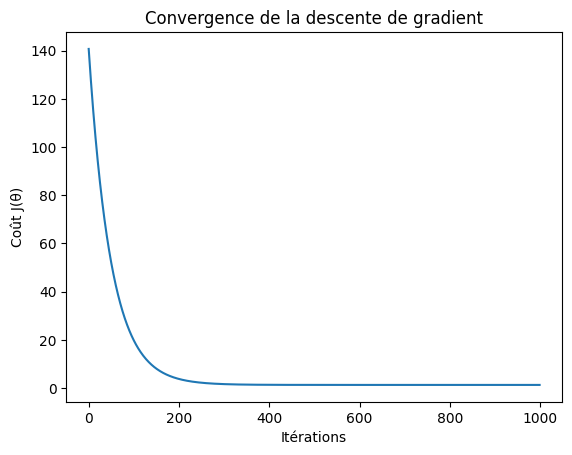

In [20]:
plt.plot(range(n_iterations), cost_history)
plt.title("Convergence de la descente de gradient")
plt.xlabel("ItÃ©rations")
plt.ylabel("CoÃ»t J(Î¸)")
plt.show()

## **Section 10 : Ã‰valuation du modÃ¨le *from scratch***

### **Coefficient de dÃ©termination $R^2$**
$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$
Plus $R^2$ est proche de $1$, meilleur est le modÃ¨le.


In [21]:
def coef_determination(y, pred):
    u = ((y - pred) ** 2).sum()         # somme des carrÃ©s des rÃ©sidus
    v = ((y - y.mean()) ** 2).sum()     # somme totale des carrÃ©s
    return 1 - u / v

In [22]:
coef_determination(Y_test, predictions)

np.float64(0.9058675472601391)

### **Valeurs rÃ©elles vs valeurs prÃ©dites**
Plus les points sont proches de la droite rouge (prÃ©diction parfaite), meilleur est le modÃ¨le.


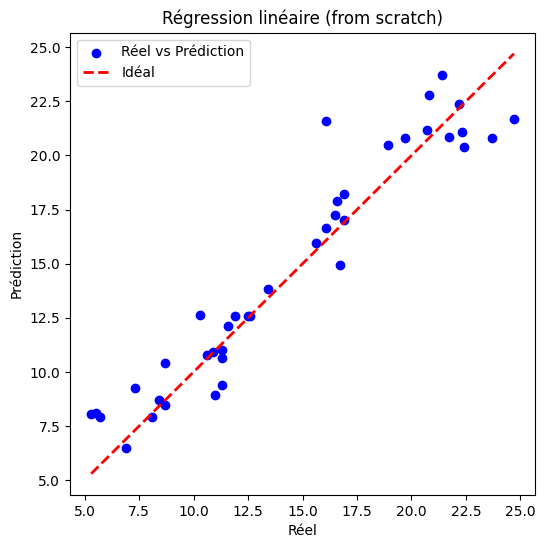

In [23]:
plt.figure(figsize=(6, 6))
plt.scatter(Y_test.ravel(), predictions.ravel(), color='blue', label='RÃ©el vs PrÃ©diction')

min_val = min(Y_test.min(), predictions.min())
max_val = max(Y_test.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='IdÃ©al')

plt.title('RÃ©gression linÃ©aire (from scratch)')
plt.xlabel('RÃ©el')
plt.ylabel('PrÃ©diction')
plt.legend()
plt.show()

### **Visualisation 3D : rÃ©el vs prÃ©dit**
Les cercles reprÃ©sentent les ventes rÃ©elles et les triangles les ventes prÃ©dites, sur l'ensemble de test (Ã©chelle d'origine des budgets).


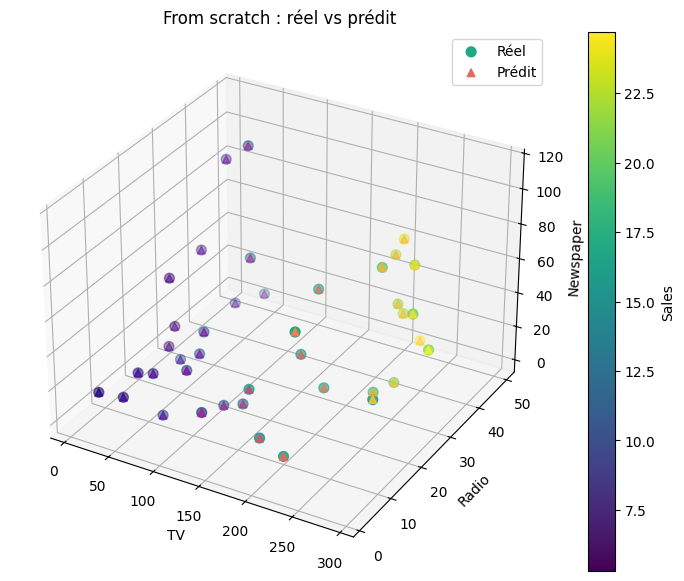

In [24]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=Y_test.ravel(), cmap="viridis", s=50, label="RÃ©el")
ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=predictions.ravel(), cmap="plasma", marker="^", s=30, label="PrÃ©dit")

ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Newspaper")
ax.set_title("From scratch : rÃ©el vs prÃ©dit")

cbar = plt.colorbar(sc)
cbar.set_label("Sales")
ax.legend()

plt.show()

## **Section 11 : ImplÃ©mentation avec Scikit-learn**
Nous rÃ©alisons maintenant la mÃªme rÃ©gression avec `LinearRegression` de Scikit-learn. Pour une comparaison Ã©quitable, nous utilisons **la mÃªme division train/test** (`random_state=42`) et la **mÃªme standardisation**. Scikit-learn gÃ¨re le biais lui-mÃªme (`fit_intercept=True`) : il n'est donc pas nÃ©cessaire d'ajouter de colonne de $1$.


In [25]:
# MÃªme division que prÃ©cÃ©demment (mÃªme random_state) -> mÃªmes donnÃ©es de test
X_train_sk, X_test_sk, Y_train_sk, Y_test_sk = train_test_split(X, Y, test_size=0.2, random_state=42)

# Standardisation (ajustÃ©e sur l'entraÃ®nement uniquement)
x_scaler = StandardScaler()
X_train_sk = x_scaler.fit_transform(X_train_sk)
X_test_sk  = x_scaler.transform(X_test_sk)

In [26]:
sklearn_model = LinearRegression(fit_intercept=True)
sklearn_model.fit(X_train_sk, Y_train_sk)
y_pred = sklearn_model.predict(X_test_sk)

print("Poids (TV, Radio, Newspaper) :", sklearn_model.coef_.ravel())
print("Biais                        :", sklearn_model.intercept_[0])

Poids (TV, Radio, Newspaper) : [4.58720774 1.48984025 0.08791597]
Biais                        : 15.330625000000001


Calcul de $R^2$ avec notre fonction personnalisÃ©e, puis des mÃ©triques officielles de Scikit-learn :


In [27]:
print("RÂ² (fonction personnalisÃ©e) :", coef_determination(Y_test_sk, y_pred))

mse = mean_squared_error(Y_test_sk, y_pred)
r2  = r2_score(Y_test_sk, y_pred)

print("Mean Squared Error (MSE)    :", mse)
print("RÂ² (scikit-learn)           :", r2)

RÂ² (fonction personnalisÃ©e) : 0.9059011844150826
Mean Squared Error (MSE)    : 2.907756910271091
RÂ² (scikit-learn)           : 0.9059011844150826


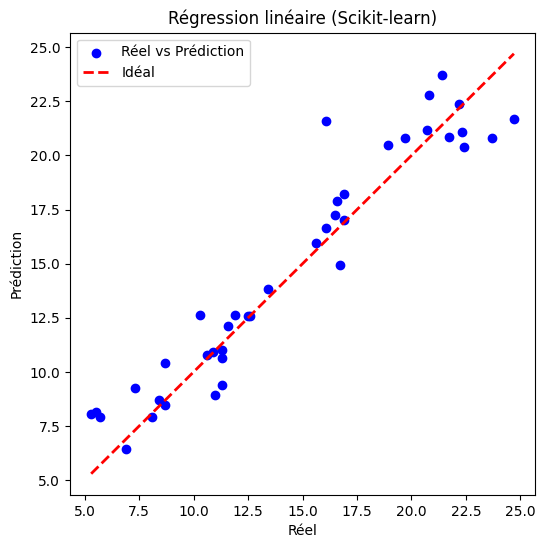

In [28]:
plt.figure(figsize=(6, 6))
plt.scatter(Y_test_sk.ravel(), y_pred.ravel(), color='blue', label='RÃ©el vs PrÃ©diction')

min_val = min(Y_test_sk.min(), y_pred.min())
max_val = max(Y_test_sk.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='IdÃ©al')

plt.title('RÃ©gression linÃ©aire (Scikit-learn)')
plt.xlabel('RÃ©el')
plt.ylabel('PrÃ©diction')
plt.legend()
plt.show()

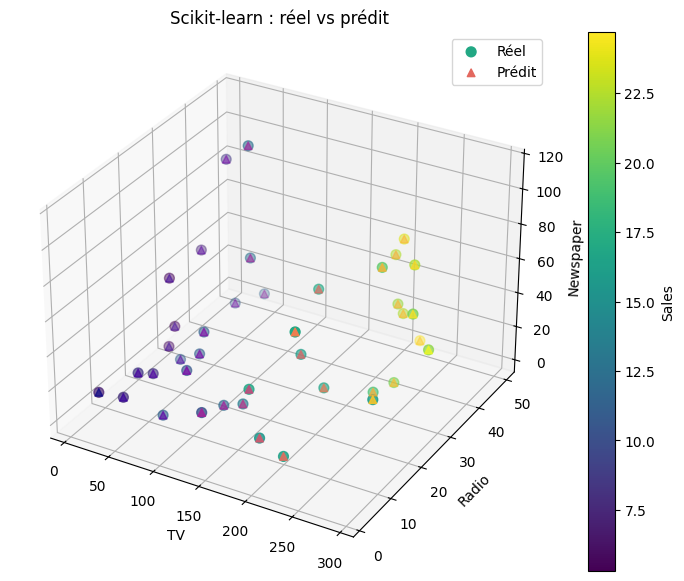

In [29]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# On utilise X_test (Ã©chelle d'origine) pour les axes, comme pour le modÃ¨le from scratch
sc = ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=Y_test_sk.ravel(), cmap="viridis", s=50, label="RÃ©el")
ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c=y_pred.ravel(), cmap="plasma", marker="^", s=30, label="PrÃ©dit")

ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Newspaper")
ax.set_title("Scikit-learn : rÃ©el vs prÃ©dit")

cbar = plt.colorbar(sc)
cbar.set_label("Sales")
ax.legend()

plt.show()

## **Section 12 : Comparaison finale des deux modÃ¨les**
Nous comparons les deux approches sur l'ensemble de test Ã  l'aide de deux mÃ©triques :
* **MSE** (erreur quadratique moyenne) : plus elle est faible, meilleur est le modÃ¨le ;
* **$R^2$** : plus il est proche de $1$, meilleur est le modÃ¨le.


In [30]:
mse_scratch = mean_squared_error(Y_test, predictions)
r2_scratch  = r2_score(Y_test, predictions)
mse_sklearn = mean_squared_error(Y_test_sk, y_pred)
r2_sklearn  = r2_score(Y_test_sk, y_pred)

print("========== FROM SCRATCH ==========")
print("MSE :", mse_scratch)
print("RÂ²  :", r2_scratch)

print("\n========== SCIKIT-LEARN ==========")
print("MSE :", mse_sklearn)
print("RÂ²  :", r2_sklearn)

comparison = pd.DataFrame({
    "ModÃ¨le": ["From Scratch", "Scikit-learn"],
    "MSE": [mse_scratch, mse_sklearn],
    "RÂ²": [r2_scratch, r2_sklearn]
})
print("\n========== COMPARAISON ==========")
print(comparison)

========== FROM SCRATCH ==========
MSE : 2.9087963353597175
RÂ²  : 0.9058675472601391

========== SCIKIT-LEARN ==========
MSE : 2.907756910271091
RÂ²  : 0.9059011844150826

========== COMPARAISON ==========
         ModÃ¨le       MSE        RÂ²
0  From Scratch  2.908796  0.905868
1  Scikit-learn  2.907757  0.905901


## **Conclusion**
Les rÃ©sultats obtenus par notre implÃ©mentation *from scratch* (descente de gradient) sont pratiquement identiques Ã  ceux de `LinearRegression` de Scikit-learn : les valeurs de $MSE$ et de $R^2$ sont quasi Ã©gales, et les coefficients appris sont trÃ¨s proches.

Cela confirme que :
1. notre implÃ©mentation de la descente de gradient est correcte et a bien convergÃ© (voir la courbe de coÃ»t) ;
2. la standardisation des variables a permis une convergence rapide et stable ;
3. Scikit-learn rÃ©sout directement le mÃªme problÃ¨me des moindres carrÃ©s, ce qui explique la similaritÃ© des rÃ©sultats.
